# SVM, RANDOM FOREST AND ADABOOST

## IMPORTING LIBRARIES

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

#### LOADING DATASET

In [21]:
columns = ["buying_price","maintenance_cost","number_of_doors","number_of_persons","lug_boot","safety","decision"]

df = pd.read_csv("car_evaluation.csv",header=None,names=columns)

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
display(df.head(5))


Number of samples: 1728
Number of features: 7


,buying_price,maintenance_cost,number_of_doors,number_of_persons,lug_boot,safety,decision
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


#### DATA ANALYSIS

In [22]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
buying_price         0
maintenance_cost     0
number_of_doors      0
number_of_persons    0
lug_boot             0
safety               0
decision             0
dtype: int64

No duplicate rows present.


In [23]:
print("\nUnique values in each column:")
for column in df.columns:
    print(column, ":", df[column].unique())


Unique values in each column:
buying_price : ['vhigh' 'high' 'med' 'low']
maintenance_cost : ['vhigh' 'high' 'med' 'low']
number_of_doors : ['2' '3' '4' '5more']
number_of_persons : ['2' '4' 'more']
lug_boot : ['small' 'med' 'big']
safety : ['low' 'med' 'high']
decision : ['unacc' 'acc' 'vgood' 'good']


In [24]:
print("\nDecision class distribution:")
print(df["decision"].value_counts())


Decision class distribution:
decision
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [25]:
# Separate input features and target
X = df.drop("decision", axis=1)
y = df["decision"]

#### ONEHOT ENCODING AND LABEL ENCODER

In [26]:
# Convert categorical input features into numeric columns
X = pd.get_dummies(X, dtype=int)

# Encode target classes into numbers
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Encoded feature shape:", X.shape)
print("Target classes:", encoder.classes_)
display(X.head())

Encoded feature shape: (1728, 21)
Target classes: ['acc' 'good' 'unacc' 'vgood']


,buying_price_high,buying_price_low,buying_price_med,buying_price_vhigh,maintenance_cost_high,maintenance_cost_low,maintenance_cost_med,maintenance_cost_vhigh,number_of_doors_2,number_of_doors_3,...,number_of_doors_5more,number_of_persons_2,number_of_persons_4,number_of_persons_more,lug_boot_big,lug_boot_med,lug_boot_small,safety_high,safety_low,safety_med
0,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,1,0
1,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,0,1
2,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,1,0,0
3,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
4,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,1


#### TRAIN TEST SPLIT

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

Training samples: 1382
Testing samples: 346
Training target distribution:
2    968
0    307
1     55
3     52
Name: count, dtype: int64

Testing target distribution:
2    242
0     77
1     14
3     13
Name: count, dtype: int64


#### MODEL TRAINING

In [28]:
# Initialize models with default hyperparameters
models = {
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training completed")

SVM training completed
Random Forest training completed
AdaBoost training completed


Random Forest training completed
AdaBoost training completed


In [29]:
for name, model in models.items():

    # Predict on training and testing data
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Calculate accuracy
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)


    print("\n", name)
    print("Training Accuracy:", round(train_acc * 100, 2), "%")
    print("Testing Accuracy:", round(test_acc * 100, 2), "%")

    print(classification_report(y_test, test_pred,target_names=encoder.classes_,zero_division=0))



 SVM
Training Accuracy: 99.28 %
Testing Accuracy: 97.4 %
              precision    recall  f1-score   support

         acc       0.91      0.97      0.94        77
        good       0.93      1.00      0.97        14
       unacc       1.00      0.98      0.99       242
       vgood       0.92      0.85      0.88        13

    accuracy                           0.97       346
   macro avg       0.94      0.95      0.94       346
weighted avg       0.98      0.97      0.97       346


 Random Forest
Training Accuracy: 100.0 %
Testing Accuracy: 96.82 %
              precision    recall  f1-score   support

         acc       0.94      0.96      0.95        77
        good       0.81      0.93      0.87        14
       unacc       0.99      0.99      0.99       242
       vgood       0.90      0.69      0.78        13

    accuracy                           0.97       346
   macro avg       0.91      0.89      0.90       346
weighted avg       0.97      0.97      0.97       346


 A

In [30]:
cv_results = []

for name, model in models.items():

    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

    cv_results.append({"Model": name,"CV Accuracy": scores.mean(),"CV Standard Deviation": scores.std()})

    print("\n", name)
    print("Fold accuracies:", scores.round(4))
    print("Mean CV Accuracy:", round(scores.mean() * 100, 2), "%")

cv_df = pd.DataFrame(cv_results)
display(cv_df)


 SVM
Fold accuracies: [0.9675 0.9422 0.9529 0.9601 0.9529]
Mean CV Accuracy: 95.51 %

 Random Forest
Fold accuracies: [0.9567 0.9422 0.9493 0.9493 0.9275]
Mean CV Accuracy: 94.5 %

 AdaBoost
Fold accuracies: [0.8556 0.8087 0.8152 0.8587 0.8514]
Mean CV Accuracy: 83.79 %


,Model,CV Accuracy,CV Standard Deviation
0,SVM,0.955138,0.008421
1,Random Forest,0.945001,0.009855
2,AdaBoost,0.837924,0.021440


#### HYPERPARAMETER TUNING

In [31]:
# 1. Define parameter grids
param_grids = {
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"],
        "gamma": ["scale", "auto"]
    },

    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },

    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 1.0]
    }
}

# 2. Perform Grid Search CV
optimized_models = {}

for name, model in models.items():

    grid = GridSearchCV(
        model,
        param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    optimized_models[name] = grid.best_estimator_

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")


# 3. Evaluate optimized models
results = {}

for name, model in optimized_models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results[name] = [accuracy, precision, recall, f1]

    print("\n", name)
    print("Testing Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))




 SVM
Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Accuracy: 99.78 %

 Random Forest
Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 94.79 %

 AdaBoost
Best Parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV Accuracy: 86.04 %

 SVM
Testing Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

 Random Forest
Testing Accuracy: 95.38 %
Precision: 0.9565
Recall: 0.9538
F1-Score: 0.953

 AdaBoost
Testing Accuracy: 83.24 %
Precision: 0.8432
Recall: 0.8324
F1-Score: 0.8304



 Random Forest
Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 94.79 %



 AdaBoost
Best Parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV Accuracy: 86.04 %

 SVM
Testing Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

 Random Forest
Testing Accuracy: 95.38 %
Precision: 0.9565
Recall: 0.9538
F1-Score: 0.953



 AdaBoost
Testing Accuracy: 83.24 %
Precision: 0.8432
Recall: 0.8324
F1-Score: 0.8304


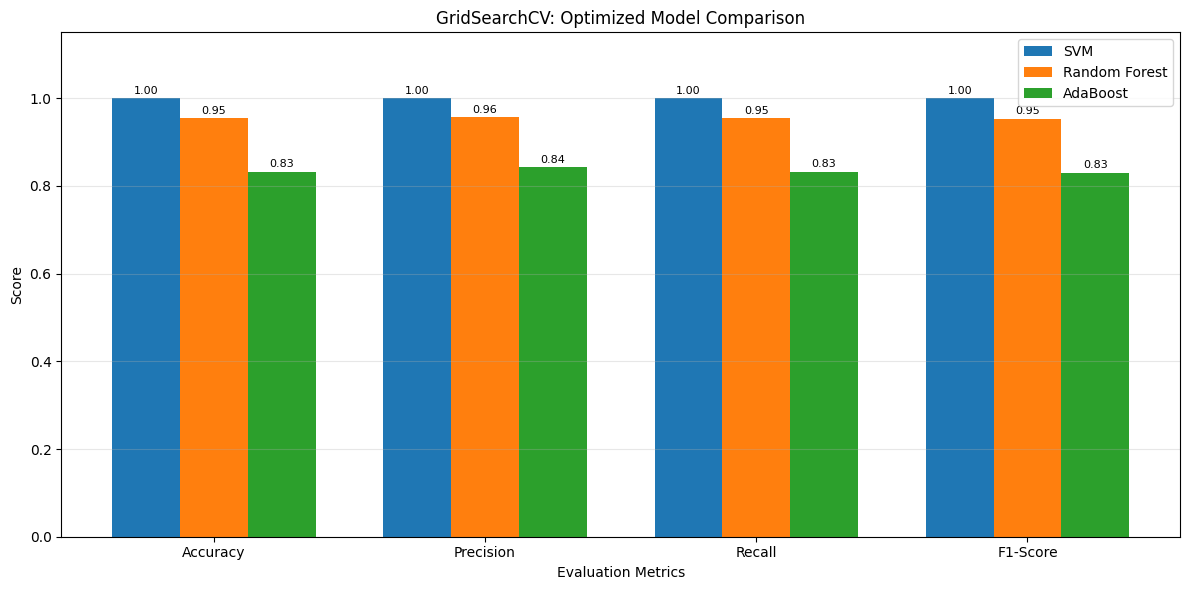

In [32]:
# 4. Plot all metrics in one graph
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))

for i, (name, scores) in enumerate(results.items()):
    bars = plt.bar(x + i * width, scores, width, label=name)

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{bar.get_height():.2f}",
            ha="center",
            fontsize=8
        )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("GridSearchCV: Optimized Model Comparison")
plt.xticks(x + width, metrics)
plt.ylim(0, 1.15)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### MODEL PERFORMANCE BEFORE AND AFTER OPTIMIZATION

In [33]:
comparison = []

for name in models:

    for stage, model in [("Before (Default)", models[name]), ("After (GridSearchCV)", optimized_models[name])]:

        y_pred = model.predict(X_test)
        cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

        comparison.append({
            "Model": name,
            "Stage": stage,
            "CV Accuracy": cv_scores.mean(),
            "CV Std": cv_scores.std(),
            "Test Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
            "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
            "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

,Model,Stage,CV Accuracy,CV Std,Test Accuracy,Precision,Recall,F1-Score
0,SVM,Before (Default),0.9551,0.0084,0.9740,0.9752,0.9740,0.9742
1,SVM,After (GridSearchCV),0.9978,0.0029,1.0000,1.0000,1.0000,1.0000
2,Random Forest,Before (Default),0.9450,0.0099,0.9682,0.9688,0.9682,0.9678
3,Random Forest,After (GridSearchCV),0.9479,0.0050,0.9538,0.9565,0.9538,0.9530
4,AdaBoost,Before (Default),0.8379,0.0214,0.8439,0.8554,0.8439,0.8394
5,AdaBoost,After (GridSearchCV),0.8604,0.0250,0.8324,0.8432,0.8324,0.8304


In [34]:
# Improvement in each metric after tuning
before = comparison_df[comparison_df["Stage"] == "Before (Default)"].set_index("Model")
after = comparison_df[comparison_df["Stage"] == "After (GridSearchCV)"].set_index("Model")

improvement = (after[["CV Accuracy", "Test Accuracy", "F1-Score"]] - before[["CV Accuracy", "Test Accuracy", "F1-Score"]]) * 100
improvement.columns = ["CV Accuracy Change (%)", "Test Accuracy Change (%)", "F1-Score Change (%)"]
display(improvement.round(2))

,CV Accuracy Change (%),Test Accuracy Change (%),F1-Score Change (%)
Model,,,
SVM,4.27,2.60,2.58
Random Forest,0.29,-1.45,-1.48
AdaBoost,2.24,-1.16,-0.90


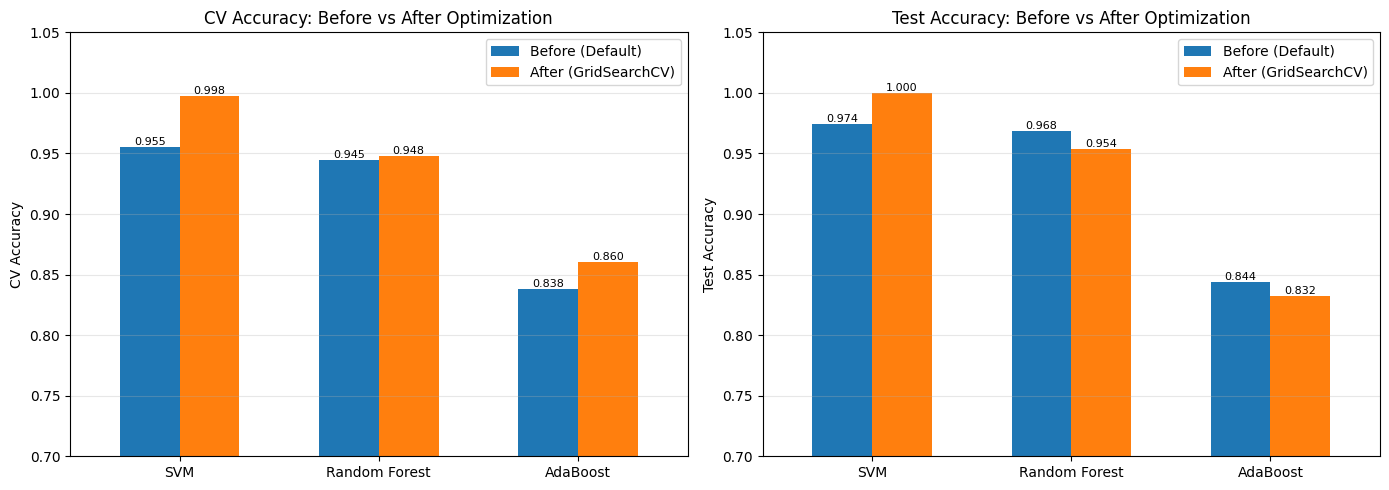

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ["CV Accuracy", "Test Accuracy"]):

    pivot = comparison_df.pivot(index="Model", columns="Stage", values=metric)
    pivot = pivot[["Before (Default)", "After (GridSearchCV)"]].loc[list(models.keys())]

    bars = pivot.plot(kind="bar", ax=ax, rot=0, width=0.6)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)

    ax.set_title(metric + ": Before vs After Optimization")
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.set_ylim(0.7, 1.05)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

#### K-FOLD CROSS VALIDATION ON SVM

In [36]:
from sklearn.model_selection import StratifiedKFold

k = 5
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

svm_default = SVC()
svm_tuned = SVC(**optimized_models["SVM"].get_params())

fold_results = []

# Manually train and test on each fold
for fold, (train_idx, val_idx) in enumerate(kfold.split(X_train, y_train), start=1):

    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    svm_default.fit(X_tr, y_tr)
    svm_tuned.fit(X_tr, y_tr)

    fold_results.append({
        "Fold": fold,
        "Train Size": len(train_idx),
        "Validation Size": len(val_idx),
        "Default SVM Accuracy": accuracy_score(y_val, svm_default.predict(X_val)),
        "Tuned SVM Accuracy": accuracy_score(y_val, svm_tuned.predict(X_val))
    })

fold_df = pd.DataFrame(fold_results)
display(fold_df.round(4))

print("Default SVM Mean Accuracy:", round(fold_df["Default SVM Accuracy"].mean() * 100, 2), "%",
      "| Std:", round(fold_df["Default SVM Accuracy"].std(ddof=0), 4))
print("Tuned SVM Mean Accuracy:  ", round(fold_df["Tuned SVM Accuracy"].mean() * 100, 2), "%",
      "| Std:", round(fold_df["Tuned SVM Accuracy"].std(ddof=0), 4))

,Fold,Train Size,Validation Size,Default SVM Accuracy,Tuned SVM Accuracy
0,1,1105,277,0.9675,0.9964
1,2,1105,277,0.9711,0.9928
2,3,1106,276,0.9674,1.0000
3,4,1106,276,0.9565,1.0000
4,5,1106,276,0.9638,0.9964


Default SVM Mean Accuracy: 96.53 % | Std: 0.005
Tuned SVM Mean Accuracy:   99.71 % | Std: 0.0027


,k,Default SVM Mean,Default SVM Std,Tuned SVM Mean,Tuned SVM Std
0,3,0.9566,0.0093,0.9913,0.0047
1,5,0.9653,0.0050,0.9971,0.0027
2,7,0.9674,0.0060,0.9978,0.0025
3,10,0.9682,0.0113,0.9993,0.0022


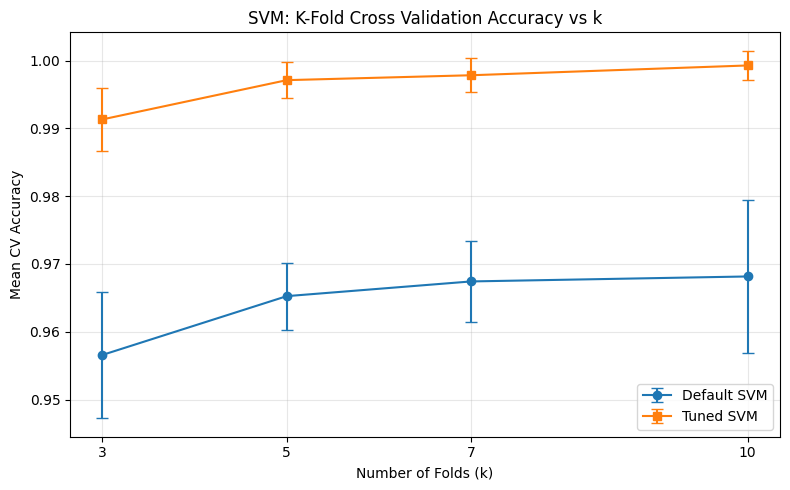

In [37]:
# Effect of the number of folds (k) on SVM cross validation accuracy
k_values = [3, 5, 7, 10]
k_results = []

for k in k_values:

    kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    default_scores = cross_val_score(SVC(), X_train, y_train, cv=kfold, scoring="accuracy")
    tuned_scores = cross_val_score(optimized_models["SVM"], X_train, y_train, cv=kfold, scoring="accuracy")

    k_results.append({
        "k": k,
        "Default SVM Mean": default_scores.mean(),
        "Default SVM Std": default_scores.std(),
        "Tuned SVM Mean": tuned_scores.mean(),
        "Tuned SVM Std": tuned_scores.std()
    })

k_df = pd.DataFrame(k_results)
display(k_df.round(4))

plt.figure(figsize=(8, 5))
plt.errorbar(k_df["k"], k_df["Default SVM Mean"], yerr=k_df["Default SVM Std"], marker="o", capsize=4, label="Default SVM")
plt.errorbar(k_df["k"], k_df["Tuned SVM Mean"], yerr=k_df["Tuned SVM Std"], marker="s", capsize=4, label="Tuned SVM")
plt.xlabel("Number of Folds (k)")
plt.ylabel("Mean CV Accuracy")
plt.title("SVM: K-Fold Cross Validation Accuracy vs k")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### CONFUSION MATRICES OF OPTIMIZED MODELS

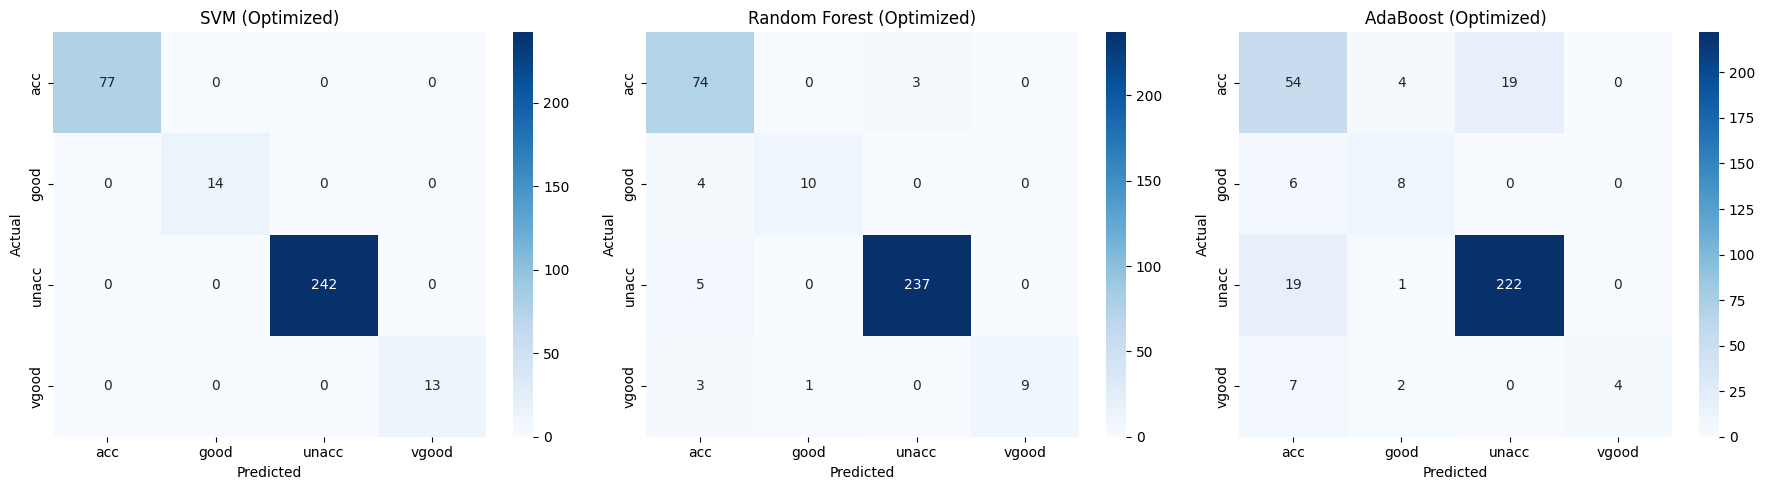

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, optimized_models.items()):

    cm = confusion_matrix(y_test, model.predict(X_test))

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)

    ax.set_title(name + " (Optimized)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()